# Logistic Regression

In [ ]:
#1 Imports
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve
)

DRIVE_PATH = "/content/drive/MyDrive/Capstone/Data_2/"

In [ ]:
#2 Loading the cleaned NHANES core data
X_train = pd.read_csv(DRIVE_PATH + "NHANES_X_train_clean.csv")
X_test = pd.read_csv(DRIVE_PATH + "NHANES_X_test_clean.csv")
y_train = pd.read_csv(DRIVE_PATH + "NHANES_y_train_clean.csv").squeeze()
y_test = pd.read_csv(DRIVE_PATH + "NHANES_y_test_clean.csv").squeeze()

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)
print("\nTrain Outcome distribution:")
print(y_train.value_counts(normalize=True))

Train shape: (1920, 5)
Test shape : (481, 5)

Train Outcome distribution:
Outcome
0    0.792708
1    0.207292
Name: proportion, dtype: float64


In [ ]:
#3 Building the Scaler + SMOTE + Logistic Regression pipeline
# Identical structure to the PIDD pipeline — scaler
# before SMOTE (distance-sensitive), SMOTE inside the pipeline for
# cross-validation-safe resampling.
lr_pipeline = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("clf", LogisticRegression(random_state=42, max_iter=2000))
])

In [ ]:
#4 Same hyperparameter search space as PIDD, for a methodologically
# consistent comparison
param_grid = [
    {"clf__solver": ["liblinear"], "clf__penalty": ["l1", "l2"], "clf__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    {"clf__solver": ["saga"], "clf__penalty": ["elasticnet"], "clf__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9], "clf__C": [0.001, 0.01, 0.1, 1, 10, 100]}
]

cv_strategy = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

In [ ]:
#5 Running GridSearchCV
lr_search = GridSearchCV(lr_pipeline, param_grid, scoring="roc_auc", cv=cv_strategy, n_jobs=-1, verbose=1)
lr_search.fit(X_train, y_train)

print("Best Parameters:", lr_search.best_params_)
print("Best CV ROC-AUC:", lr_search.best_score_)

best_lr_nhanes = lr_search.best_estimator_

Fitting 10 folds for each of 42 candidates, totalling 420 fits
Best Parameters: {'clf__C': 1, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}
Best CV ROC-AUC: 0.919566034240957


In [ ]:
#6 Evaluating on the NHANES test set
y_pred = best_lr_nhanes.predict(X_test)
y_prob = best_lr_nhanes.predict_proba(X_test)[:, 1]

print("="*50)
print("NHANES LOGISTIC REGRESSION RESULTS")
print("="*50)
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob):.4f}")
print("\nClassification Report")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

NHANES LOGISTIC REGRESSION RESULTS
Accuracy : 0.8836
Precision: 0.6774
Recall   : 0.8400
F1 Score : 0.7500
ROC AUC  : 0.9282

Classification Report
              precision    recall  f1-score   support

           0       0.96      0.90      0.92       381
           1       0.68      0.84      0.75       100

    accuracy                           0.88       481
   macro avg       0.82      0.87      0.84       481
weighted avg       0.90      0.88      0.89       481


Confusion Matrix
[[341  40]
 [ 16  84]]


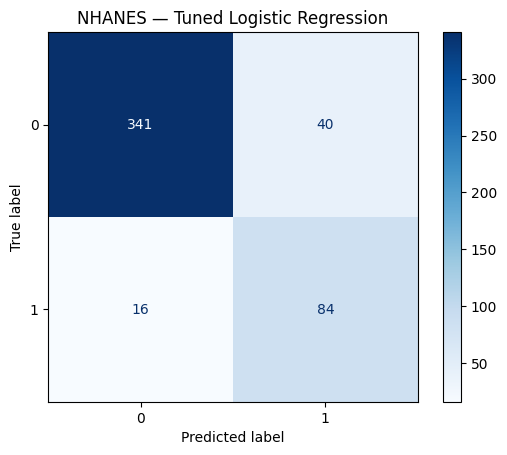

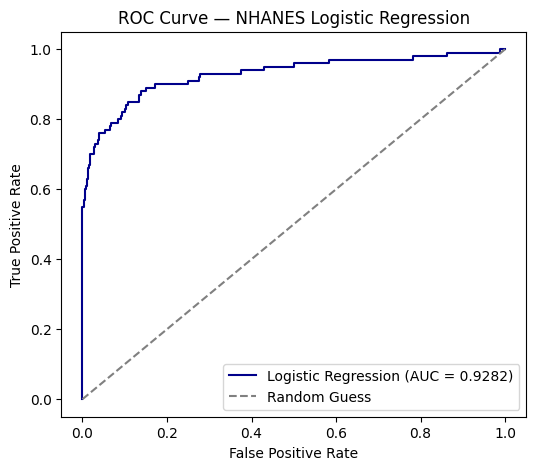

In [ ]:
#7 Confusion Matrix + ROC Curve
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("NHANES — Tuned Logistic Regression")
plt.savefig(DRIVE_PATH + "G4_NHANES_LR_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="darkblue", label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob):.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — NHANES Logistic Regression")
plt.legend(loc="lower right")
plt.savefig(DRIVE_PATH + "G4_NHANES_LR_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Confirm the confusion matrix numbers match expectations from G3
print("Test set positives:", 16 + 84)
print("Test set negatives:", 341 + 40)

Test set positives: 100
Test set negatives: 381


In [ ]:
#8 Coefficients
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": best_lr_nhanes.named_steps["clf"].coef_[0]
}).sort_values(by="Coefficient", key=abs, ascending=False)
print(coef_df)

         Feature  Coefficient
0        Glucose     3.117236
4            Age     0.950421
2            BMI     0.340066
1  BloodPressure    -0.175856
3        Insulin     0.091494


In [ ]:
import os

print(os.listdir("/content/drive/MyDrive"))

['Play Books Notes', 'Naledi-klasnotas-graad-12-2018.pdf', 'Motivation.docx', 'T4_GraphsofTrigFunction_BP_9_22_14.pdf', 'MATHS-FUNCTIONS.pdf', '202455031_Kudzanai_Tauzeni.pdf', 'Colab Notebooks', 'K_Tauzeni_ NSC.pdf', 'K_Tauzeni ID.pdf', 'Father_Affidavit.pdf', 'Mother_Affidavit.pdf', 'Capstone', 'Document from Kudzi 🌱', 'DIRISA Practise', 'WhatsApp Chat with Goitsemodimo']


In [ ]:
import joblib

joblib.dump(
    best_lr_nhanes,
    "/content/drive/MyDrive/Capstone/models/nhanes_logistic_regression_pipeline.pkl"
)
print("Saved")

Saved


In [ ]:
#X Diagnostic: how much of Outcome comes from the Glucose criterion alone?
glucose_only_flag = (X_train["Glucose"] >= 126)
print("Patients labeled diabetic where Glucose alone triggers Outcome=1:")
print(pd.crosstab(glucose_only_flag, y_train))

Patients labeled diabetic where Glucose alone triggers Outcome=1:
Outcome     0    1
Glucose           
False    1470  148
True       52  250


# Random Forest

In [ ]:
#1 Imports
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
# (pd, plt, joblib, ImbPipeline, SMOTE, metrics, DRIVE_PATH, X_train/X_test/y_train/y_test, cv_strategy — same as G4)

In [ ]:
#2 Building the SMOTE + Random Forest pipeline (no scaler — tree-based)
rf_pipeline = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("clf", RandomForestClassifier(random_state=42, n_jobs=-1))
])

param_dist = {
    "clf__n_estimators": [100, 200, 300, 400, 500],
    "clf__max_depth": [None, 5, 10, 15, 20],
    "clf__min_samples_split": [2, 5, 10],
    "clf__min_samples_leaf": [1, 2, 4],
    "clf__max_features": ["sqrt", "log2"],
    "clf__bootstrap": [True, False]
}

In [ ]:
#3 Running RandomizedSearchCV
rf_search = RandomizedSearchCV(rf_pipeline, param_dist, n_iter=50, scoring="roc_auc", cv=cv_strategy, random_state=42, n_jobs=-1, verbose=1)
rf_search.fit(X_train, y_train)

print("Best Parameters:", rf_search.best_params_)
print("Best CV ROC-AUC:", rf_search.best_score_)

best_rf_nhanes = rf_search.best_estimator_

Fitting 10 folds for each of 50 candidates, totalling 500 fits
Best Parameters: {'clf__n_estimators': 400, 'clf__min_samples_split': 2, 'clf__min_samples_leaf': 4, 'clf__max_features': 'log2', 'clf__max_depth': 5, 'clf__bootstrap': True}
Best CV ROC-AUC: 0.9141705531740362


In [ ]:
 #4 Evaluating on the NHANES test set
y_pred_rf = best_rf_nhanes.predict(X_test)
y_prob_rf = best_rf_nhanes.predict_proba(X_test)[:, 1]

print("="*50)
print("NHANES RANDOM FOREST RESULTS")
print("="*50)
print(f"Accuracy : {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred_rf):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob_rf):.4f}")
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_rf))

NHANES RANDOM FOREST RESULTS
Accuracy : 0.8960
Precision: 0.7232
Recall   : 0.8100
F1 Score : 0.7642
ROC AUC  : 0.9463

Confusion Matrix
[[350  31]
 [ 19  81]]


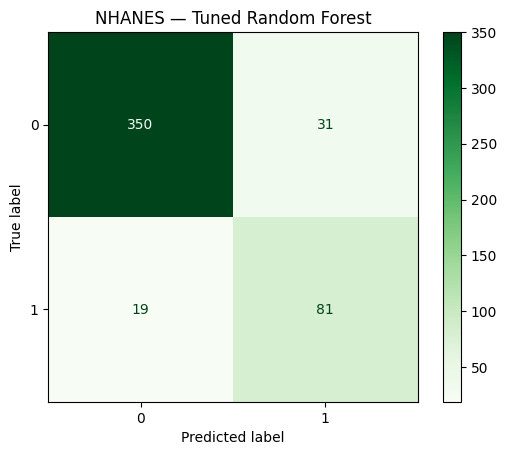

         Feature  Importance
0        Glucose    0.655921
4            Age    0.204717
3        Insulin    0.054077
2            BMI    0.048048
1  BloodPressure    0.037238


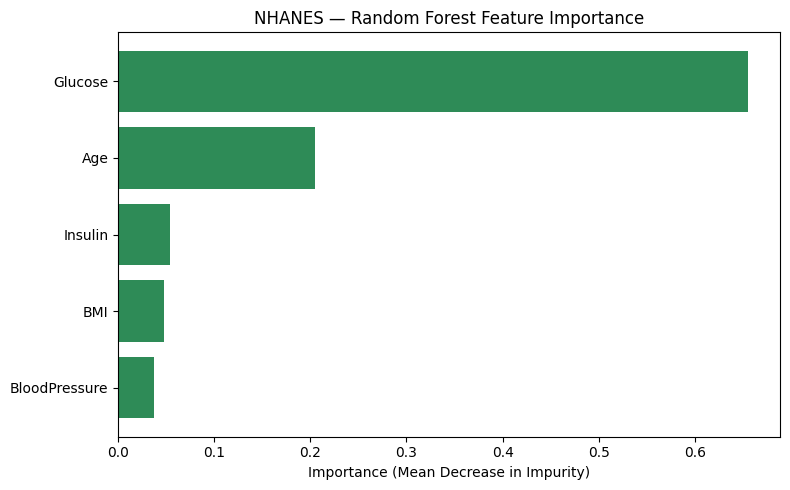

In [ ]:
#5 Confusion Matrix, ROC Curve, Feature Importance — same pattern as PIDD RF (Section 4.Y)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, cmap="Greens")
plt.title("NHANES — Tuned Random Forest")
plt.savefig(DRIVE_PATH + "G5_NHANES_RF_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

feat_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf_nhanes.named_steps["clf"].feature_importances_
}).sort_values(by="Importance", ascending=False)
print(feat_importance_df)

plt.figure(figsize=(8, 5))
plt.barh(feat_importance_df["Feature"], feat_importance_df["Importance"], color="seagreen")
plt.gca().invert_yaxis()
plt.xlabel("Importance (Mean Decrease in Impurity)")
plt.title("NHANES — Random Forest Feature Importance")
plt.tight_layout()
plt.savefig(DRIVE_PATH + "G5_NHANES_RF_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
#6 Saving the model
joblib.dump(
    best_rf_nhanes,
    "/content/drive/MyDrive/Capstone/models/nhanes_random_forest_pipeline.pkl"
)
print("Saved")

Saved


# XGBOOST

In [ ]:
#1 Imports
from xgboost import XGBClassifier

In [ ]:
#2 Building the SMOTE + XGBoost pipeline
xgb_pipeline = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("clf", XGBClassifier(random_state=42, eval_metric="logloss", n_jobs=-1))
])

param_dist = {
    "clf__n_estimators": [100, 200, 300, 400, 500],
    "clf__max_depth": [3, 4, 5, 6, 8],
    "clf__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "clf__subsample": [0.6, 0.8, 1.0],
    "clf__colsample_bytree": [0.6, 0.8, 1.0],
    "clf__min_child_weight": [1, 3, 5],
    "clf__gamma": [0, 0.1, 0.3],
    "clf__reg_alpha": [0, 0.1, 1],
    "clf__reg_lambda": [1, 1.5, 2]
}

In [ ]:
#3 Running RandomizedSearchCV
xgb_search = RandomizedSearchCV(xgb_pipeline, param_dist, n_iter=50, scoring="roc_auc", cv=cv_strategy, random_state=42, n_jobs=-1, verbose=1)
xgb_search.fit(X_train, y_train)

print("Best Parameters:", xgb_search.best_params_)
print("Best CV ROC-AUC:", xgb_search.best_score_)

best_xgb_nhanes = xgb_search.best_estimator_

Fitting 10 folds for each of 50 candidates, totalling 500 fits
Best Parameters: {'clf__subsample': 1.0, 'clf__reg_lambda': 1.5, 'clf__reg_alpha': 0.1, 'clf__n_estimators': 500, 'clf__min_child_weight': 3, 'clf__max_depth': 3, 'clf__learning_rate': 0.01, 'clf__gamma': 0.3, 'clf__colsample_bytree': 0.8}
Best CV ROC-AUC: 0.9166787768582465


In [ ]:
#4 Evaluating on the NHANES test set
y_pred_xgb = best_xgb_nhanes.predict(X_test)
y_prob_xgb = best_xgb_nhanes.predict_proba(X_test)[:, 1]

print("="*50)
print("NHANES XGBOOST RESULTS")
print("="*50)
print(f"Accuracy : {accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_xgb):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_xgb):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred_xgb):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob_xgb):.4f}")
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_xgb))

NHANES XGBOOST RESULTS
Accuracy : 0.8981
Precision: 0.7339
Recall   : 0.8000
F1 Score : 0.7656
ROC AUC  : 0.9416

Confusion Matrix
[[352  29]
 [ 20  80]]


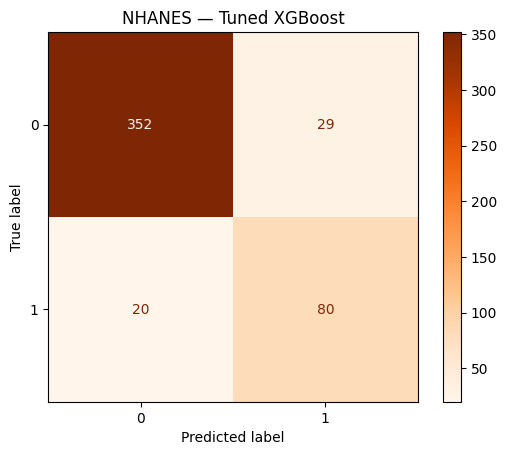

         Feature  Importance
0        Glucose    0.589220
4            Age    0.196609
1  BloodPressure    0.082998
2            BMI    0.069440
3        Insulin    0.061732


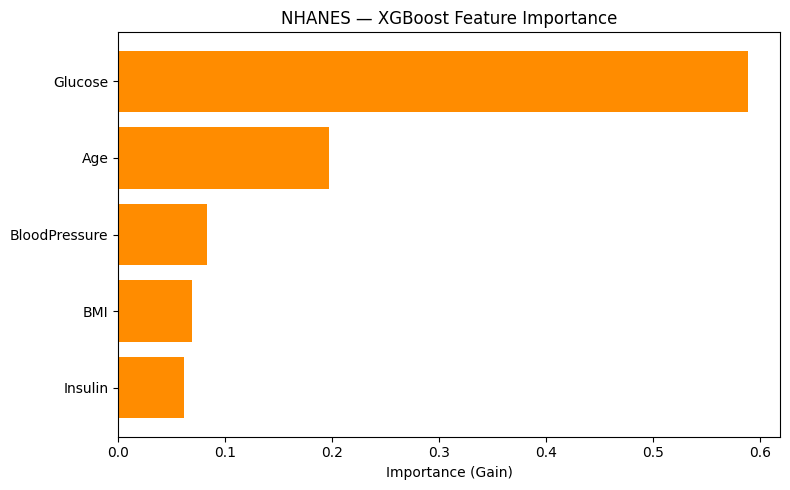

In [ ]:
#5 Confusion Matrix, Feature Importance
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_xgb, cmap="Oranges")
plt.title("NHANES — Tuned XGBoost")
plt.savefig(DRIVE_PATH + "G6_NHANES_XGB_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

feat_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_xgb_nhanes.named_steps["clf"].feature_importances_
}).sort_values(by="Importance", ascending=False)
print(feat_importance_df)

plt.figure(figsize=(8, 5))
plt.barh(feat_importance_df["Feature"], feat_importance_df["Importance"], color="darkorange")
plt.gca().invert_yaxis()
plt.xlabel("Importance (Gain)")
plt.title("NHANES — XGBoost Feature Importance")
plt.tight_layout()
plt.savefig(DRIVE_PATH + "G6_NHANES_XGB_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
#6 Saving the model
joblib.dump(
    best_xgb_nhanes,
    "/content/drive/MyDrive/Capstone/models/nhanes_xgboost_pipeline.pkl"
)
print("Saved")

Saved


In [ ]:
#7 Three-model comparison table — NHANES independently trained
comparison_df = pd.DataFrame({
    "Logistic Regression": [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred), recall_score(y_test, y_pred), f1_score(y_test, y_pred), roc_auc_score(y_test, y_prob)],
    "Random Forest": [accuracy_score(y_test, y_pred_rf), precision_score(y_test, y_pred_rf), recall_score(y_test, y_pred_rf), f1_score(y_test, y_pred_rf), roc_auc_score(y_test, y_prob_rf)],
    "XGBoost": [accuracy_score(y_test, y_pred_xgb), precision_score(y_test, y_pred_xgb), recall_score(y_test, y_pred_xgb), f1_score(y_test, y_pred_xgb), roc_auc_score(y_test, y_prob_xgb)]
}, index=["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"])
print(comparison_df.round(4))

           Logistic Regression  Random Forest  XGBoost
Accuracy                0.8836         0.8960   0.8981
Precision               0.6774         0.7232   0.7339
Recall                  0.8400         0.8100   0.8000
F1-Score                0.7500         0.7642   0.7656
ROC-AUC                 0.9282         0.9463   0.9416
